# Lab 1 - Part 2 : Multi class classification with PyTorch (Predictive Maintenance)
Dataset : https://www.kaggle.com/datasets/shivamb/machine-predictive-maintenance-classification

The goal is to predict the **Failure Type** of a machine (6 classes in the raw data, 5 after cleaning).

In [1]:
!pip install -q skorch kagglehub imbalanced-learn


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, confusion_matrix

from imblearn.over_sampling import SMOTE
from skorch import NeuralNetClassifier

torch.manual_seed(42)
np.random.seed(42)

In [3]:
import kagglehub, os
path = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "predictive_maintenance.csv"))
df.head()

c:\Users\moham\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['predictive_maintenance.csv']


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


## 1. Preprocessing (cleaning + standardization)

In [4]:
print(df.shape)
df.info()
print(df.isnull().sum())
print("duplicates :", df.duplicated().sum())

(10000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm] 

In [5]:
# UDI and Product ID are just ids, they dont help the model
df = df.drop(columns=["UDI", "Product ID"])

# rename columns to make them easier to use
df.columns = ["Type", "air_temp", "process_temp", "rpm", "torque", "tool_wear", "Target", "Failure_Type"]

# check if Target and Failure_Type are coherent
pd.crosstab(df["Target"], df["Failure_Type"])

Failure_Type,Heat Dissipation Failure,No Failure,Overstrain Failure,Power Failure,Random Failures,Tool Wear Failure
Target,,,,,,
0,0,9643,0,0,18,0
1,112,9,78,95,0,45


In [6]:
# some rows say Target=1 but 'No Failure' (or the opposite) -> they are incoherent so we remove them
bad = ((df["Target"] == 1) & (df["Failure_Type"] == "No Failure")) | ((df["Target"] == 0) & (df["Failure_Type"] != "No Failure"))
print("incoherent rows :", bad.sum())
df = df[~bad].reset_index(drop=True)
# note : all the 'Random Failures' rows have Target=0, so they are removed here -> we end with 5 classes
print(df["Failure_Type"].value_counts())

# Target is the same info as Failure_Type so we drop it (else it is data leakage)
df = df.drop(columns=["Target"])

# encode Type (L, M, H) as numbers
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

# encode the label
le = LabelEncoder()
df["label"] = le.fit_transform(df["Failure_Type"])
print(dict(zip(le.classes_, range(len(le.classes_)))))
df.head()

incoherent rows : 27
Failure_Type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64
{'Heat Dissipation Failure': 0, 'No Failure': 1, 'Overstrain Failure': 2, 'Power Failure': 3, 'Tool Wear Failure': 4}


,Type,air_temp,process_temp,rpm,torque,tool_wear,Failure_Type,label
0,1,298.1,308.6,1551,42.8,0,No Failure,1
1,0,298.2,308.7,1408,46.3,3,No Failure,1
2,0,298.1,308.5,1498,49.4,5,No Failure,1
3,0,298.2,308.6,1433,39.5,7,No Failure,1
4,0,298.2,308.7,1408,40.0,9,No Failure,1


## 2. Exploratory Data Analysis

In [7]:
df.describe()

,Type,air_temp,process_temp,rpm,torque,tool_wear,label
count,9973.000000,9973.000000,9973.000000,9973.000000,9973.000000,9973.000000,9973.000000
mean,0.500050,300.003259,310.004031,1538.893212,39.978993,107.921087,1.029179
std,0.670959,2.000548,1.483692,179.412171,9.966805,63.649152,0.311323
min,0.000000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,0.000000,298.300000,308.800000,1423.000000,33.200000,53.000000,1.000000
50%,0.000000,300.100000,310.100000,1503.000000,40.100000,108.000000,1.000000
75%,1.000000,301.500000,311.100000,1612.000000,46.700000,162.000000,1.000000
max,2.000000,304.500000,313.800000,2886.000000,76.600000,253.000000,4.000000


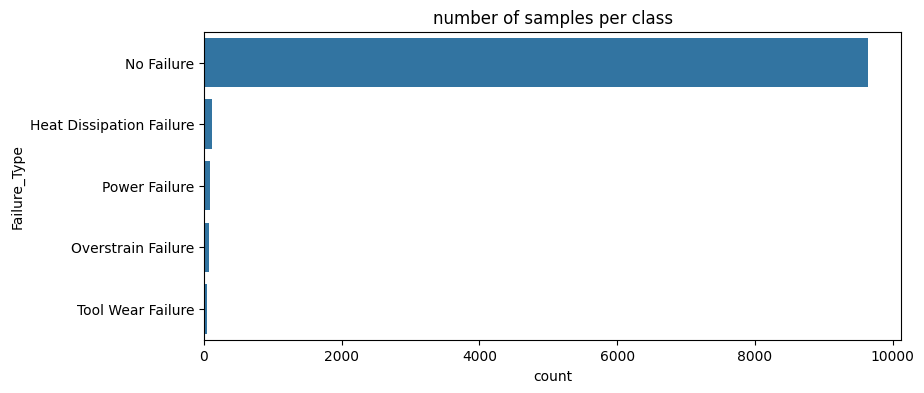

Failure_Type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Name: count, dtype: int64


In [8]:
# class distribution -> very unbalanced
plt.figure(figsize=(9, 4))
sns.countplot(y=df["Failure_Type"], order=df["Failure_Type"].value_counts().index)
plt.title("number of samples per class")
plt.show()
print(df["Failure_Type"].value_counts())

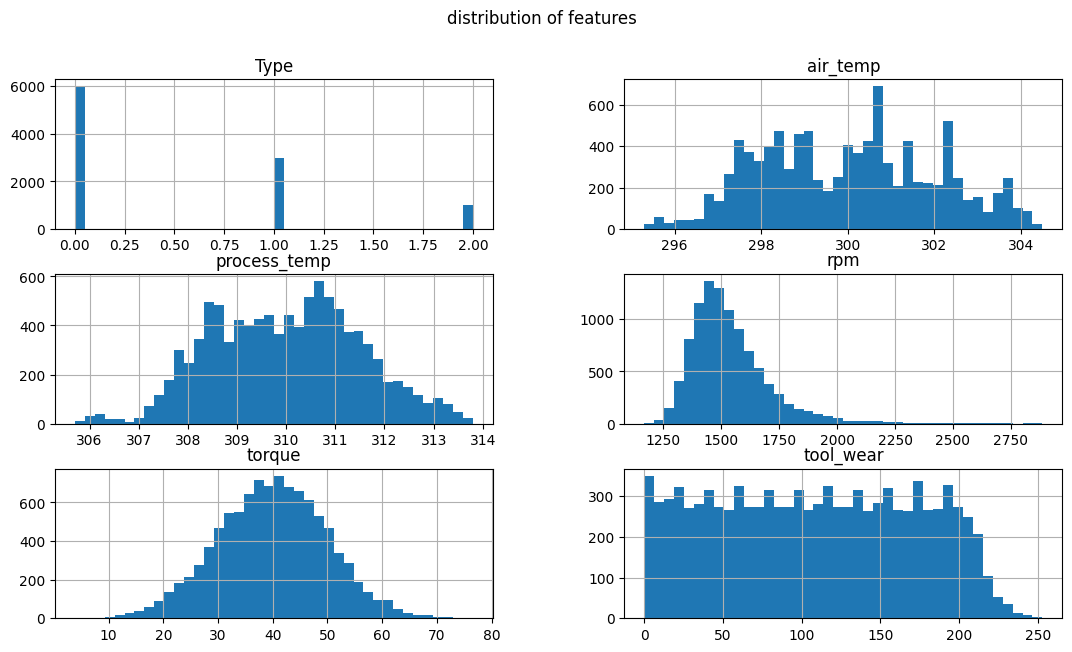

In [9]:
feats = ["Type", "air_temp", "process_temp", "rpm", "torque", "tool_wear"]
df[feats].hist(bins=40, figsize=(13, 7))
plt.suptitle("distribution of features")
plt.show()

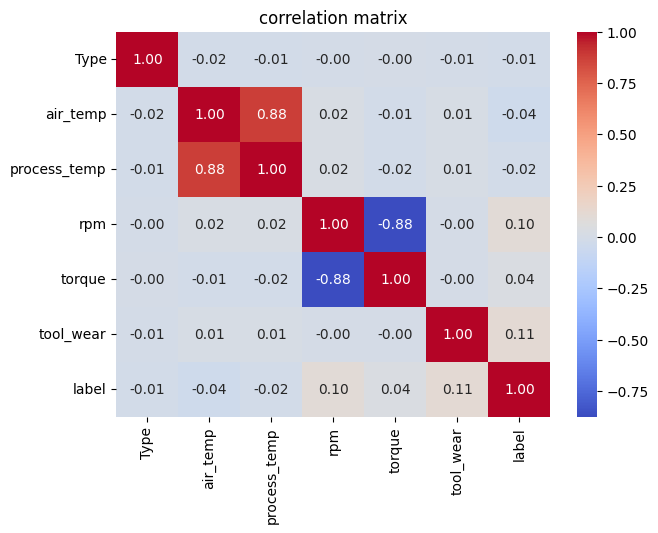

In [10]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[feats + ["label"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("correlation matrix")
plt.show()

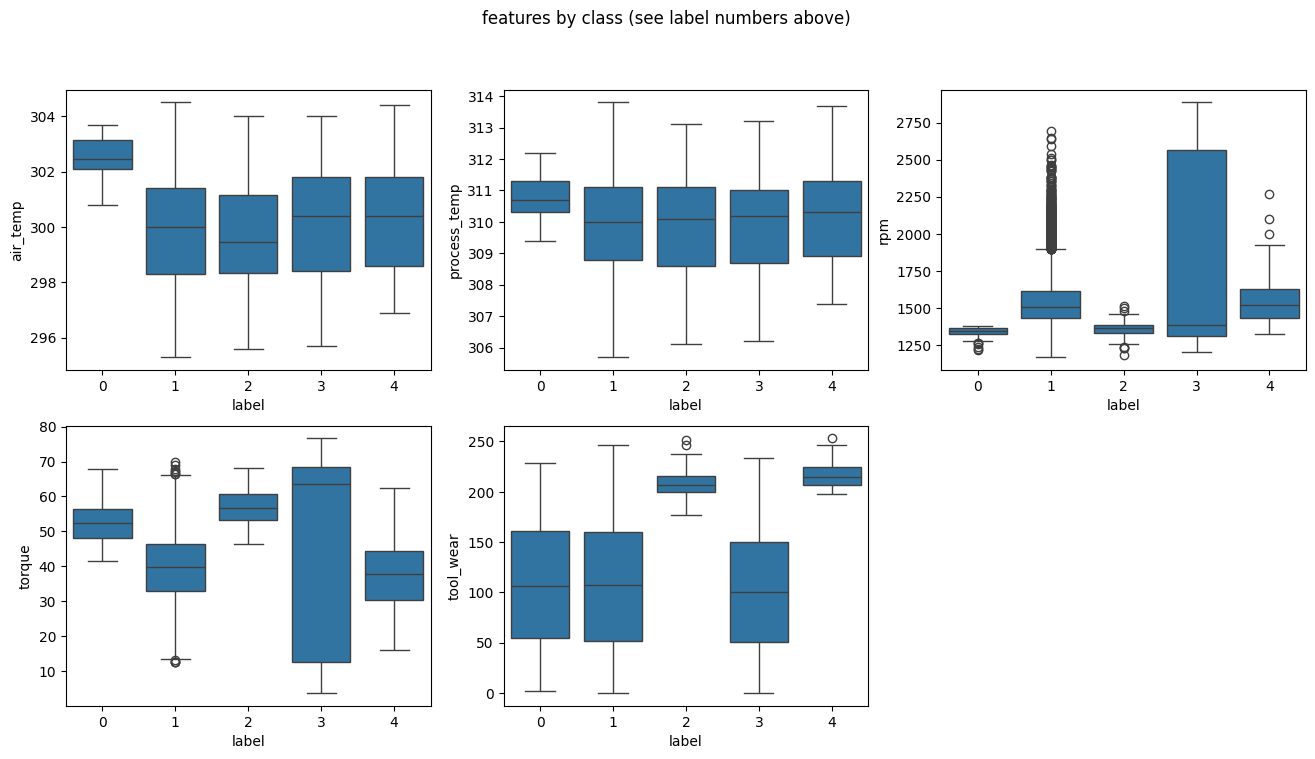

In [11]:
# boxplot of each feature by failure type
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
for i, f in enumerate(feats[1:]):
    sns.boxplot(data=df, x="label", y=f, ax=ax[i // 3][i % 3])
ax[1][2].axis("off")
plt.suptitle("features by class (see label numbers above)")
plt.show()

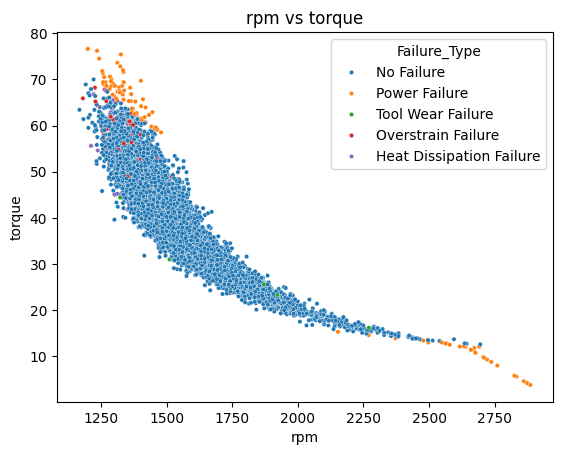

In [12]:
sns.scatterplot(data=df, x="rpm", y="torque", hue="Failure_Type", s=10)
plt.title("rpm vs torque")
plt.show()

**What we see :** the dataset is very unbalanced (~96% of "No Failure"). Air temp and process temp are very correlated,
rpm and torque are negatively correlated. Power failures happen with very low or very high torque, tool wear failures
happen when tool_wear is high, and heat dissipation failures are linked to low rpm.

## Split + standardization

In [13]:
X = df[feats].values
y = df["label"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
print(X_train.shape, X_test.shape)

(7978, 6) (1995, 6)


## 3. Data augmentation to balance the dataset
We use **SMOTE** (it creates new synthetic samples of the small classes). We do it **only on the train set**, the test stays real.

before : [  90 7714   62   76   36]
after  : [7714 7714 7714 7714 7714]


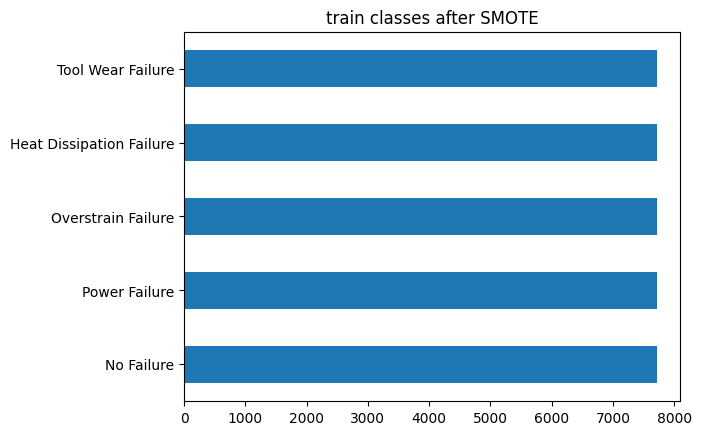

In [14]:
print("before :", np.bincount(y_train))
sm = SMOTE(random_state=42, k_neighbors=3)
X_train_bal, y_train_bal = sm.fit_resample(X_train, y_train)
print("after  :", np.bincount(y_train_bal))

X_train_bal = X_train_bal.astype(np.float32)
y_train_bal = y_train_bal.astype(np.int64)
X_test = X_test.astype(np.float32)
y_test = y_test.astype(np.int64)
X_train = X_train.astype(np.float32)
y_train = y_train.astype(np.int64)

pd.Series(le.inverse_transform(y_train_bal)).value_counts().plot(kind="barh", title="train classes after SMOTE")
plt.show()

## 4. DNN architecture with PyTorch

In [15]:
n_classes = len(le.classes_)

class ClfNet(nn.Module):
    def __init__(self, n_in=6, hidden=64, n_layers=2, n_out=n_classes, dropout=0.0, batchnorm=False):
        super().__init__()
        layers = []
        size = n_in
        for i in range(n_layers):
            layers.append(nn.Linear(size, hidden))
            if batchnorm:
                layers.append(nn.BatchNorm1d(hidden))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            size = hidden
        layers.append(nn.Linear(size, n_out))  # no softmax, CrossEntropyLoss does it
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

print(ClfNet())

ClfNet(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=5, bias=True)
  )
)


## 5. GridSearch for the best hyper-parameters

In [ ]:
net = NeuralNetClassifier(
    ClfNet,
    criterion=nn.CrossEntropyLoss,
    batch_size=128,
    train_split=None,
    verbose=0,
)

params = {
    "lr": [0.01, 0.001],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [20, 40],
    "module__hidden": [32, 64],
    "module__n_layers": [2, 3],
}

# random subset of the balanced train set so the grid search is faster
idx = np.random.choice(len(X_train_bal), 10000, replace=False)
gs = GridSearchCV(net, params, cv=3, scoring="f1_macro", n_jobs=1, verbose=1)
gs.fit(X_train_bal[idx], y_train_bal[idx])

print("best params :", gs.best_params_)
print("best f1 macro (cv) :", gs.best_score_)

Fitting 3 folds for each of 32 candidates, totalling 96 fits


In [ ]:
res = pd.DataFrame(gs.cv_results_)
res[["params", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(10)

,params,mean_test_score
12,"{'lr': 0.01, 'max_epochs': 40, 'module__hidden...",0.989403
14,"{'lr': 0.01, 'max_epochs': 40, 'module__hidden...",0.986994
30,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.986304
10,"{'lr': 0.01, 'max_epochs': 40, 'module__hidden...",0.985254
8,"{'lr': 0.01, 'max_epochs': 40, 'module__hidden...",0.984175
6,"{'lr': 0.01, 'max_epochs': 20, 'module__hidden...",0.983505
2,"{'lr': 0.01, 'max_epochs': 20, 'module__hidden...",0.981989
0,"{'lr': 0.01, 'max_epochs': 20, 'module__hidden...",0.980657
28,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.980574
26,"{'lr': 0.001, 'max_epochs': 40, 'module__hidde...",0.978370


## 6. Train the best model + Loss / Epochs and Accuracy / Epochs

In [ ]:
def train_model(model, optimizer, epochs, X_train, y_train, X_test, y_test, batch_size=128, l1=0.0):
    loss_fn = nn.CrossEntropyLoss()
    Xtr = torch.tensor(X_train); ytr = torch.tensor(y_train)
    Xte = torch.tensor(X_test); yte = torch.tensor(y_test)

    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch_size):
            idx = perm[i:i + batch_size]
            out = model(Xtr[idx])
            loss = loss_fn(out, ytr[idx])
            if l1 > 0:
                loss = loss + l1 * sum(p.abs().sum() for p in model.parameters())
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        model.eval()
        with torch.no_grad():
            otr = model(Xtr); ote = model(Xte)
            hist["train_loss"].append(loss_fn(otr, ytr).item())
            hist["test_loss"].append(loss_fn(ote, yte).item())
            hist["train_acc"].append((otr.argmax(1) == ytr).float().mean().item())
            hist["test_acc"].append((ote.argmax(1) == yte).float().mean().item())

        if ep % 10 == 0 or ep == epochs - 1:
            print(f"epoch {ep} | train loss {hist['train_loss'][-1]:.4f} | test loss {hist['test_loss'][-1]:.4f} | train acc {hist['train_acc'][-1]:.4f} | test acc {hist['test_acc'][-1]:.4f}")
    return hist


def plot_hist(hist, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(hist["train_loss"], label="train")
    ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title("Loss / Epochs " + title); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(hist["train_acc"], label="train")
    ax[1].plot(hist["test_acc"], label="test")
    ax[1].set_title("Accuracy / Epochs " + title); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.show()

epoch 0 | train loss 0.0929 | test loss 0.3117 | train acc 0.9730 | test acc 0.8992


epoch 10 | train loss 0.0277 | test loss 0.2260 | train acc 0.9929 | test acc 0.9499


epoch 20 | train loss 0.0279 | test loss 0.2468 | train acc 0.9929 | test acc 0.9579


epoch 30 | train loss 0.0156 | test loss 0.2732 | train acc 0.9966 | test acc 0.9634


epoch 39 | train loss 0.0243 | test loss 0.2801 | train acc 0.9940 | test acc 0.9619


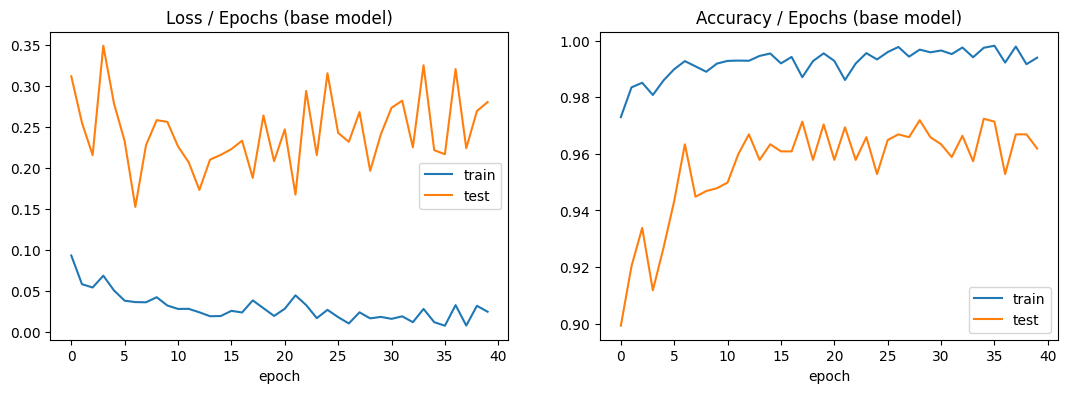

In [ ]:
bp = gs.best_params_
model1 = ClfNet(hidden=bp["module__hidden"], n_layers=bp["module__n_layers"])
opt1 = bp["optimizer"](model1.parameters(), lr=bp["lr"])

hist1 = train_model(model1, opt1, bp["max_epochs"], X_train_bal, y_train_bal, X_test, y_test)
plot_hist(hist1, "(base model)")

**Interpretation :** the train loss keeps going down, but the test loss goes down and then stays flat or goes up a bit,
this means the model starts to overfit the synthetic SMOTE samples. Test accuracy is high, but we have to be careful
because 96% of the test set is "No Failure", so accuracy alone is not enough -> we look at the other metrics.

## 7. Metrics on train and test

In [ ]:
def get_metrics(model, X, y, name):
    model.eval()
    with torch.no_grad():
        p = model(torch.tensor(X)).argmax(1).numpy()
    return {
        "data": name,
        "accuracy": accuracy_score(y, p),
        "precision (macro)": precision_score(y, p, average="macro", zero_division=0),
        "sensitivity/recall (macro)": recall_score(y, p, average="macro", zero_division=0),
        "f1 (macro)": f1_score(y, p, average="macro", zero_division=0),
        "f1 (weighted)": f1_score(y, p, average="weighted", zero_division=0),
    }

pd.DataFrame([
    get_metrics(model1, X_train_bal, y_train_bal, "train (balanced)"),
    get_metrics(model1, X_train, y_train, "train (original)"),
    get_metrics(model1, X_test, y_test, "test"),
])

,data,accuracy,precision (macro),sensitivity/recall (macro),f1 (macro),f1 (weighted)
0,train (balanced),0.994037,0.994043,0.994037,0.994029,0.994029
1,train (original),0.980948,0.731900,0.977541,0.811187,0.984093
2,test,0.961905,0.573911,0.782700,0.645036,0.968574


                          precision    recall  f1-score   support

Heat Dissipation Failure       0.57      0.91      0.70        22
              No Failure       0.99      0.97      0.98      1929
      Overstrain Failure       0.63      0.75      0.69        16
           Power Failure       0.55      0.84      0.67        19
       Tool Wear Failure       0.12      0.44      0.19         9

                accuracy                           0.96      1995
               macro avg       0.57      0.78      0.65      1995
            weighted avg       0.98      0.96      0.97      1995



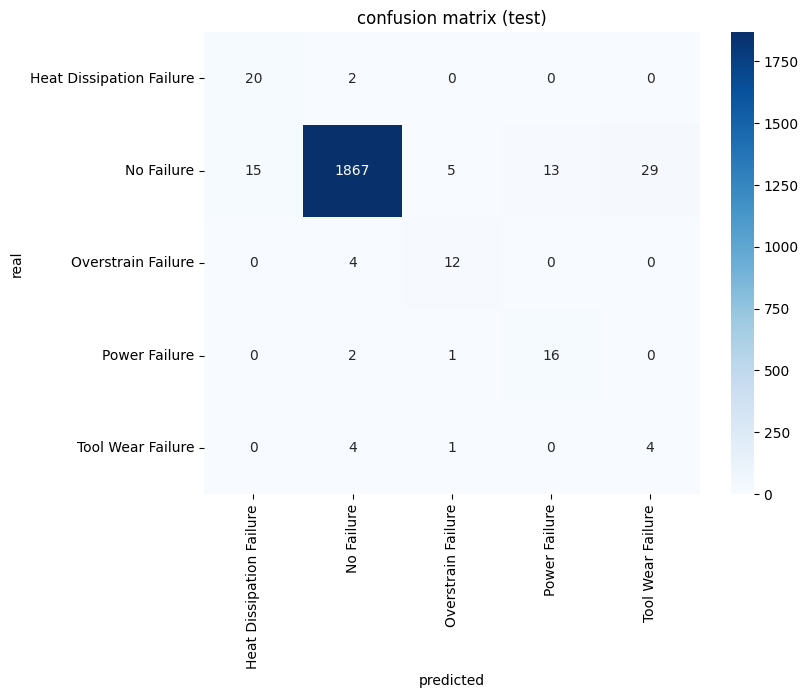

In [ ]:
model1.eval()
with torch.no_grad():
    p_test = model1(torch.tensor(X_test)).argmax(1).numpy()

print(classification_report(y_test, p_test, target_names=le.classes_, zero_division=0))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, p_test), annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("predicted"); plt.ylabel("real")
plt.title("confusion matrix (test)")
plt.show()

In [ ]:
# specificity for each class (sensitivity is the recall above)
cm = confusion_matrix(y_test, p_test)
for i, c in enumerate(le.classes_):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fn - fp
    print(f"{c:28s} sensitivity = {tp / (tp + fn):.3f}   specificity = {tn / (tn + fp):.3f}")

Heat Dissipation Failure     sensitivity = 0.909   specificity = 0.992
No Failure                   sensitivity = 0.968   specificity = 0.818
Overstrain Failure           sensitivity = 0.750   specificity = 0.996
Power Failure                sensitivity = 0.842   specificity = 0.993
Tool Wear Failure            sensitivity = 0.444   specificity = 0.985


## 8. Regularization techniques

In [ ]:
results = [dict(model="base", **get_metrics(model1, X_test, y_test, "test"))]
histories = {"base": hist1}
E = bp["max_epochs"]
OPT = bp["optimizer"]

configs = {
    "dropout":   dict(dropout=0.3, batchnorm=False, wd=0.0, l1=0.0),
    "L2":        dict(dropout=0.0, batchnorm=False, wd=1e-3, l1=0.0),
    "L1":        dict(dropout=0.0, batchnorm=False, wd=0.0, l1=1e-5),
    "batchnorm": dict(dropout=0.0, batchnorm=True,  wd=0.0, l1=0.0),
    "all":       dict(dropout=0.3, batchnorm=True,  wd=1e-3, l1=1e-5),
}

for name, c in configs.items():
    print("=====", name)
    m = ClfNet(hidden=bp["module__hidden"], n_layers=bp["module__n_layers"], dropout=c["dropout"], batchnorm=c["batchnorm"])
    o = OPT(m.parameters(), lr=bp["lr"], weight_decay=c["wd"])
    h = train_model(m, o, E, X_train_bal, y_train_bal, X_test, y_test, l1=c["l1"])
    histories[name] = h
    results.append(dict(model=name, **get_metrics(m, X_test, y_test, "test")))

===== dropout


epoch 0 | train loss 0.1074 | test loss 0.3814 | train acc 0.9663 | test acc 0.8471


epoch 10 | train loss 0.0555 | test loss 0.2644 | train acc 0.9819 | test acc 0.9113


epoch 20 | train loss 0.0477 | test loss 0.2341 | train acc 0.9866 | test acc 0.9248


epoch 30 | train loss 0.0477 | test loss 0.2546 | train acc 0.9858 | test acc 0.9218


...

epoch 0 | train loss 0.1124 | test loss 0.3844 | train acc 0.9670 | test acc 0.8591


epoch 10 | train loss 0.0933 | test loss 0.2867 | train acc 0.9761 | test acc 0.8877


epoch 20 | train loss 0.0862 | test loss 0.3179 | train acc 0.9745 | test acc 0.8887


epoch 30 | train loss 0.0834 | test loss 0.2850 | train acc 0.9775 | test acc 0.9043


epoch 39 | train loss 0.0970 | test loss 0.3879 | train acc 0.9704 | test acc 0.8712


In [ ]:
pd.DataFrame(results).drop(columns="data")

,model,accuracy,precision (macro),sensitivity/recall (macro),f1 (macro),f1 (weighted)
0,base,0.961905,0.573911,0.782700,0.645036,0.968574
1,dropout,0.924812,0.511204,0.897247,0.608763,0.947725
2,L2,0.927318,0.513141,0.887343,0.605469,0.948750
3,L1,0.968922,0.615561,0.807474,0.687815,0.974698
4,batchnorm,0.960401,0.586418,0.811129,0.660326,0.968908
5,all,0.871178,0.445137,0.951236,0.540043,0.914565


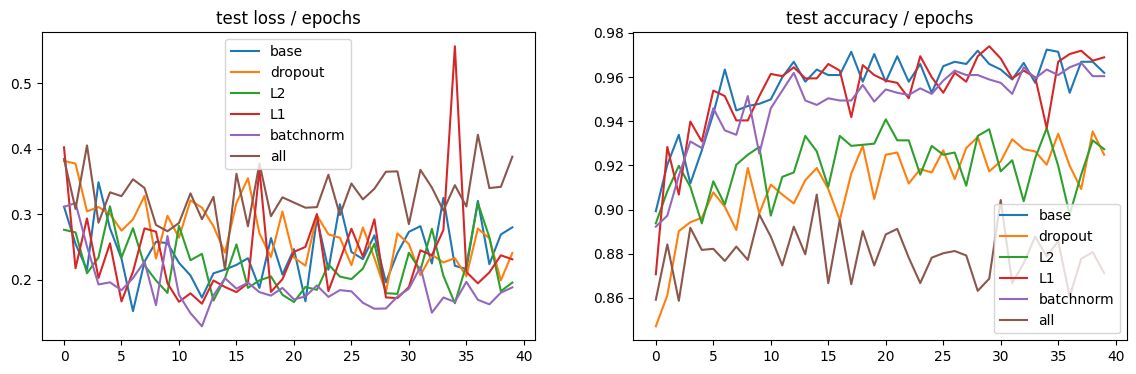

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for name, h in histories.items():
    ax[0].plot(h["test_loss"], label=name)
    ax[1].plot(h["test_acc"], label=name)
ax[0].set_title("test loss / epochs"); ax[0].legend()
ax[1].set_title("test accuracy / epochs"); ax[1].legend()
plt.show()

**Comparison :**
- **L1** gives the best macro f1 and accuracy on the test set, and **BatchNorm** is also a bit better than the base model.
- **Dropout** and **L2** reduce the gap between train and test loss (less overfitting on the SMOTE samples) and give a higher
  recall (they find more failures), but the precision goes down (more false alarms), so the macro f1 is a bit lower.
- **All together** is too much regularization : very high recall but low precision and the lowest accuracy.
- For predictive maintenance missing a failure is worse than a false alarm, so a model with higher recall (dropout / L2) can also be a good choice.
- The hardest class is **Tool Wear Failure** (only 9 samples in the test set).